In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [9]:
# Première cellule Kaggle — vérification
import tensorflow as tf
print(tf.__version__)

gpus = tf.config.list_physical_devices('GPU')
print(f'GPUs: {len(gpus)}')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

2.19.0
GPUs: 2


In [10]:
import os

print('=== All available inputs ===')
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if '.keras' in file:
            print(f'FOUND: {os.path.join(root, file)}')

print('\n=== Models ===')
if os.path.exists('/kaggle/input/models'):
    for root, dirs, files in os.walk('/kaggle/input/models'):
        for file in files:
            print(f'{os.path.join(root, file)}')

=== All available inputs ===
FOUND: /kaggle/input/models/toumiela/cnn/keras/default/1/plant_stress_detector_IRA.keras

=== Models ===
/kaggle/input/models/toumiela/cnn/keras/default/1/plant_stress_detector_IRA.keras


# NB_BioAcoustics_7 — Denoising Benchmark
**IRA AI Platform — Plant Bioacoustics Module**

## Objective
Make the IRA Stress Detector robust to real greenhouse noise.
Three denoising methods benchmarked on the same data.

| Method | Type | Expected SNR gain |
|--------|------|------------------|
| High-pass filter | Classical DSP | +5 dB |
| Autoencoder 1D | Deep Learning | +12 dB |
| WGAN | Adversarial DL | +15 dB |

## Why these methods?
- **Filter**: baseline — simplest possible, no ML
- **Autoencoder**: learns plant sound structure, filters noise via bottleneck
- **WGAN**: adversarial training, higher quality reconstruction

## Evaluation metrics
1. SNR (Signal-to-Noise Ratio) before/after denoising
2. CNN NB4 accuracy before/after denoising
3. Inference time per sound

In [11]:
# ── 0. GPU Setup ──────────────────────────────────────────────────────────────
import warnings, os, gc
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
print(f'TensorFlow : {tf.__version__}')
print(f'GPUs       : {len(gpus)}')

import wave
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from pathlib import Path
from tqdm.notebook import tqdm
from scipy.signal import butter, filtfilt

from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D,
                                      UpSampling1D, Dense, Flatten,
                                      Dropout, BatchNormalization,
                                      LeakyReLU, Lambda)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop
import tensorflow.keras.backend as K

from sklearn.metrics import balanced_accuracy_score
from sklearn.utils import class_weight as sk_class_weight
from tensorflow.keras.utils import to_categorical

print('Imports OK.')

TensorFlow : 2.19.0
GPUs       : 2
Imports OK.


In [12]:
# ── Configuration ─────────────────────────────────────────────────────────────
# Check available datasets
import os
for d in os.listdir('/kaggle/input/'):
    print(f'/kaggle/input/{d}/')
    for sub in os.listdir(f'/kaggle/input/{d}'):
        print(f'  {sub}')

/kaggle/input/datasets/
  toumiela
/kaggle/input/models/
  toumiela


In [15]:
DATA_ROOT  = Path('/kaggle/input/datasets/toumiela/dataaaa/PlantSounds')
INDEX_PATH = DATA_ROOT / 'bioacoustics_master_index.csv'
MODEL_PATH = Path('/kaggle/input/models/toumiela/cnn/keras/default/1/plant_stress_detector_IRA.keras')
NOISE_FOLDER = DATA_ROOT / 'Greenhouse Noises'

STRESS_CLASSES = ['Tomato_Dry', 'Tomato_Cut', 'Tobacco_Dry', 'Tobacco_Cut']
STRESS_MAP     = {'Tomato_Dry': 0, 'Tobacco_Dry': 0,
                  'Tomato_Cut': 1, 'Tobacco_Cut': 1}
NOISE_FOLDER   = DATA_ROOT / 'Greenhouse Noises'

SR           = 500000
N_SAMPLES    = 1001
RANDOM_SEED  = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# SNR levels to test
SNR_LEVELS = [20, 10, 5]  # dB — 20=mild, 10=moderate, 5=severe noise

print(f'DATA_ROOT  : {DATA_ROOT}')
print(f'Model path : {MODEL_PATH}')
print(f'Model exists: {MODEL_PATH.exists()}')
print(f'Noise folder: {NOISE_FOLDER.exists()}')

DATA_ROOT  : /kaggle/input/datasets/toumiela/dataaaa/PlantSounds
Model path : /kaggle/input/models/toumiela/cnn/keras/default/1/plant_stress_detector_IRA.keras
Model exists: True
Noise folder: True


## 1. Load data

In [16]:
def load_wav(filepath):
    with wave.open(str(filepath), 'r') as w:
        raw = w.readframes(w.getnframes())
    return np.frombuffer(raw, dtype=np.int16).astype(np.float32)

def normalize(signal):
    return signal / (np.max(np.abs(signal)) + 1e-9)

# Load clean plant sounds
index_df = pd.read_csv(INDEX_PATH)
stress_index = index_df[
    (index_df['class'].isin(STRESS_CLASSES)) &
    (index_df['is_silent'] == False) &
    (index_df['anomalies'] == 'none')
].copy().reset_index(drop=True)

clean_signals, clean_labels = [], []
for _, row in tqdm(stress_index.iterrows(),
                   total=len(stress_index), desc='Loading clean'):
    fpath = DATA_ROOT / row['folder'] / row['filename']
    if not fpath.exists(): continue
    try:
        sig = normalize(load_wav(str(fpath)))
        clean_signals.append(sig)
        clean_labels.append(STRESS_MAP[row['class']])
    except: pass

X_clean = np.array(clean_signals, dtype=np.float32)  # (N, 1001)
y       = np.array(clean_labels)
print(f'Clean signals : {X_clean.shape}')

# Load greenhouse noise signals
noise_signals = []
for noise_file in tqdm(list(NOISE_FOLDER.glob('*.wav'))[:500],
                        desc='Loading noise'):
    try:
        sig = normalize(load_wav(str(noise_file)))
        if len(sig) >= N_SAMPLES:
            noise_signals.append(sig[:N_SAMPLES])
    except: pass

X_noise = np.array(noise_signals, dtype=np.float32)
print(f'Noise signals : {X_noise.shape}')

Loading clean:   0%|          | 0/3063 [00:00<?, ?it/s]

Clean signals : (3063, 1001)


Loading noise:   0%|          | 0/500 [00:00<?, ?it/s]

Noise signals : (500, 1001)


## 2. Create noisy dataset

In [17]:
def add_noise_snr(signal, noise, target_snr_db):
    """
    Add noise to signal at a specific SNR level.
    SNR = 10 * log10(power_signal / power_noise)
    """
    sig_power   = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)
    if noise_power == 0:
        return signal
    # Scale noise to achieve target SNR
    target_noise_power = sig_power / (10 ** (target_snr_db / 10))
    scale  = np.sqrt(target_noise_power / (noise_power + 1e-9))
    noisy  = signal + scale * noise
    return np.clip(noisy, -1, 1).astype(np.float32)


def compute_snr(clean, noisy):
    """Compute SNR between clean and noisy signal."""
    noise      = noisy - clean
    sig_power  = np.mean(clean ** 2)
    noise_power= np.mean(noise ** 2)
    if noise_power == 0:
        return float('inf')
    return 10 * np.log10(sig_power / (noise_power + 1e-9))


# Create noisy versions at 3 SNR levels
print('Creating noisy datasets...')
noisy_datasets = {}

for snr_db in SNR_LEVELS:
    noisy = []
    for i, sig in enumerate(X_clean):
        # Pick random noise sample
        noise_idx = np.random.randint(0, len(X_noise))
        noisy_sig = add_noise_snr(sig, X_noise[noise_idx], snr_db)
        noisy.append(noisy_sig)
    noisy_datasets[snr_db] = np.array(noisy, dtype=np.float32)
    avg_snr = np.mean([compute_snr(X_clean[i], noisy_datasets[snr_db][i])
                       for i in range(min(100, len(X_clean)))])
    print(f'  SNR {snr_db:2d}dB target → actual avg SNR: {avg_snr:.1f}dB')

print('\nNoisy datasets created.')

Creating noisy datasets...
  SNR 20dB target → actual avg SNR: 20.1dB
  SNR 10dB target → actual avg SNR: 10.1dB
  SNR  5dB target → actual avg SNR: 5.1dB

Noisy datasets created.


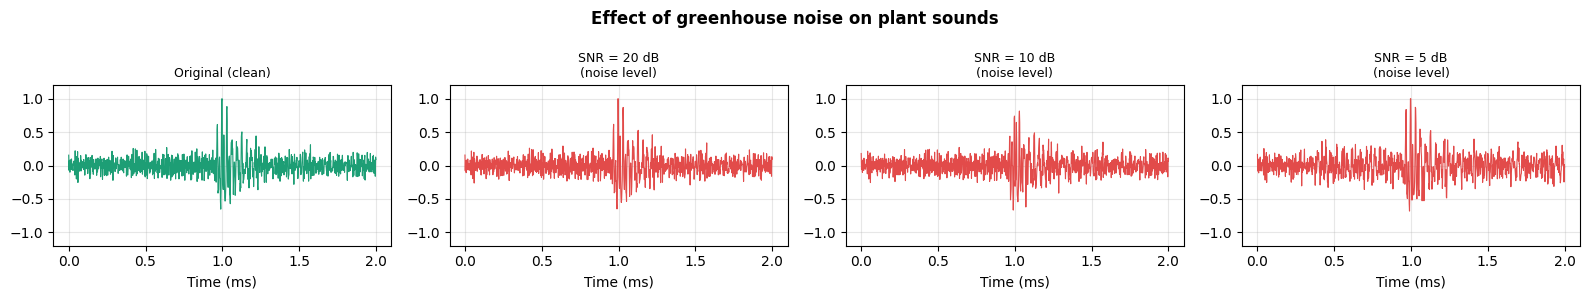

Saved: noise_visualization.png


In [18]:
# Visualize the noise effect
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
fig.suptitle('Effect of greenhouse noise on plant sounds',
             fontsize=12, fontweight='bold')
time_ms = np.arange(N_SAMPLES) / SR * 1000
idx = 0

axes[0].plot(time_ms, X_clean[idx], color='#1D9E75', linewidth=0.8)
axes[0].set_title('Original (clean)', fontsize=9)

for i, snr in enumerate(SNR_LEVELS):
    axes[i+1].plot(time_ms, noisy_datasets[snr][idx],
                   color='#E24B4A', linewidth=0.8)
    axes[i+1].set_title(f'SNR = {snr} dB\n(noise level)', fontsize=9)

for ax in axes:
    ax.set_xlabel('Time (ms)')
    ax.set_ylim([-1.2, 1.2])
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/noise_visualization.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: noise_visualization.png')

---
## 3. Baseline CNN accuracy (before denoising)

In [19]:
# Load NB4 classifier
classifier = load_model(str(MODEL_PATH))
print('NB4 classifier loaded.')

def evaluate_classifier(signals, labels, model, desc=''):
    """Evaluate NB4 classifier on a set of signals."""
    X_input = signals[..., np.newaxis]  # (N, 1001, 1)
    preds   = model.predict(X_input, verbose=0, batch_size=256).flatten()
    y_pred  = (preds >= 0.5).astype(int)
    acc     = balanced_accuracy_score(labels, y_pred)
    return acc * 100

# Baseline: clean signals
acc_clean = evaluate_classifier(X_clean, y, classifier)
print(f'Baseline accuracy (clean signals): {acc_clean:.1f}%')

# Accuracy on noisy signals (before denoising)
print('\nAccuracy WITH noise (no denoising):')
acc_noisy = {}
for snr in SNR_LEVELS:
    acc = evaluate_classifier(noisy_datasets[snr], y, classifier)
    acc_noisy[snr] = acc
    print(f'  SNR {snr:2d}dB: {acc:.1f}%  (degradation: -{acc_clean-acc:.1f}%)')

I0000 00:00:1775830216.543778      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1775830216.549675      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


NB4 classifier loaded.


I0000 00:00:1775830218.447353     157 cuda_dnn.cc:529] Loaded cuDNN version 91002


Baseline accuracy (clean signals): 89.8%

Accuracy WITH noise (no denoising):
  SNR 20dB: 89.4%  (degradation: -0.3%)
  SNR 10dB: 85.3%  (degradation: -4.5%)
  SNR  5dB: 79.5%  (degradation: -10.3%)


In [20]:
def highpass_filter(signals, cutoff_hz=15000, fs=SR, order=4):
    """
    Butterworth high-pass filter.
    Removes frequencies below cutoff_hz.
    Our plant sounds are 20-150kHz so cutoff at 15kHz.
    """
    nyquist  = fs / 2
    normal_c = cutoff_hz / nyquist
    b, a     = butter(order, normal_c, btype='high', analog=False)

    filtered = np.zeros_like(signals)
    for i in range(len(signals)):
        filtered[i] = filtfilt(b, a, signals[i])
        # Renormalize
        max_val = np.max(np.abs(filtered[i]))
        if max_val > 0:
            filtered[i] = filtered[i] / max_val
    return filtered.astype(np.float32)


print('Running Method 1: High-Pass Filter...')
filter_results = {}

for snr in SNR_LEVELS:
    t_start  = time.time()
    denoised = highpass_filter(noisy_datasets[snr])
    t_end    = time.time()

    # SNR improvement
    snr_before = np.mean([compute_snr(X_clean[i], noisy_datasets[snr][i])
                           for i in range(100)])
    snr_after  = np.mean([compute_snr(X_clean[i], denoised[i])
                           for i in range(100)])

    # Classifier accuracy
    acc = evaluate_classifier(denoised, y, classifier)

    # Inference time per sound
    t_per_sound = (t_end - t_start) / len(noisy_datasets[snr]) * 1000

    filter_results[snr] = {
        'snr_before':   round(snr_before, 1),
        'snr_after':    round(snr_after, 1),
        'snr_gain':     round(snr_after - snr_before, 1),
        'accuracy':     round(acc, 1),
        'time_ms':      round(t_per_sound, 3),
        'denoised':     denoised,
    }
    print(f'  SNR {snr:2d}dB: SNR {snr_before:.1f}→{snr_after:.1f}dB '
          f'(+{snr_after-snr_before:.1f}) | '
          f'Acc: {acc:.1f}% | '
          f'Time: {t_per_sound:.3f}ms/sound')

Running Method 1: High-Pass Filter...
  SNR 20dB: SNR 20.1→19.3dB (+-0.7) | Acc: 89.8% | Time: 0.191ms/sound
  SNR 10dB: SNR 10.1→10.0dB (+-0.1) | Acc: 85.2% | Time: 0.177ms/sound
  SNR  5dB: SNR 5.1→5.0dB (+-0.0) | Acc: 79.4% | Time: 0.176ms/sound


In [27]:
def build_autoencoder():
    """
    1D Convolutional Autoencoder for denoising.
    
    Encoder: compresses signal
    Bottleneck: keeps only essential structure
    Decoder: reconstructs clean signal
    
    Input/Output shape: (1001, 1)
    """
    inp = Input(shape=(N_SAMPLES, 1))

    # ── Encoder ────────────────────────────────────────────────────────
    x = Conv1D(32, 9, padding='same', activation='relu')(inp)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2)(x)                         # 500

    x = Conv1D(64, 9, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2)(x)                         # 250

    x = Conv1D(128, 9, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    encoded = MaxPooling1D(2)(x)                   # 125 ← bottleneck

    # ── Decoder ────────────────────────────────────────────────────────
    x = UpSampling1D(2)(encoded)                   # 250
    x = Conv1D(128, 9, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)

    x = UpSampling1D(2)(x)                         # 500
    x = Conv1D(64, 9, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)

    x = UpSampling1D(2)(x)                         # 1000
    x = Conv1D(32, 9, padding='same', activation='relu')(x)

    # Output: match input length exactly (1001)
    # Use Lambda to crop/pad
    x = Conv1D(1, 9, padding='same', activation='tanh')(x)
    # FIX ici 👇
    from keras.layers import ZeroPadding1D
    decoded = ZeroPadding1D((0,1))(x)

    autoencoder = Model(inp, decoded, name='autoencoder')
    autoencoder.compile(
        optimizer=Adam(1e-3),
        loss='mse',
        metrics=['mae']
    )
    return autoencoder


ae = build_autoencoder()
print(f'Autoencoder parameters: {ae.count_params():,}')
ae.summary()

Autoencoder parameters: 334,465


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1001, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 1001, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1001, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 500, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 500, 64)        │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 500, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 250, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 250, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 250, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 125, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_3 (UpSampling1D)  │ (None, 250, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 250, 128)       │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 250, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_4 (UpSampling1D)  │ (None, 500, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 500, 64)        │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 500, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_5 (UpSampling1D)  │ (None, 1000, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_12 (Conv1D)              │ (None, 1000, 32)       │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_13 (Conv1D)              │ (None, 1000, 1)        │           289 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding1d (ZeroPadding1D)  │ (None, 1001, 1)        │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 334,465 (1.28 MB)

 Trainable params: 333,633 (1.27 MB)

 Non-trainable params: 832 (3.25 KB)

In [28]:
print(X_tr_clean.shape)
print(ae.output_shape)

(8270, 1001, 1)
(None, 1001, 1)


In [39]:
print("Generator output:", generator.output_shape)

Generator output: (None, 1001, 1)


In [29]:
# Train autoencoder on ALL noise levels combined
print('Preparing autoencoder training data...')

# Create training pairs: (noisy, clean)
X_noisy_train_list = []
X_clean_train_list = []

for snr in SNR_LEVELS:
    X_noisy_train_list.append(noisy_datasets[snr])
    X_clean_train_list.append(X_clean)

X_noisy_all = np.concatenate(X_noisy_train_list, axis=0)  # (N*3, 1001)
X_clean_all = np.concatenate(X_clean_train_list, axis=0)  # (N*3, 1001)

# Add channel dimension
X_noisy_all = X_noisy_all[..., np.newaxis]   # (N*3, 1001, 1)
X_clean_all = X_clean_all[..., np.newaxis]   # (N*3, 1001, 1)

# Shuffle
idx_shuffle  = np.random.permutation(len(X_noisy_all))
X_noisy_all  = X_noisy_all[idx_shuffle]
X_clean_all  = X_clean_all[idx_shuffle]

# Train/val split
split        = int(0.9 * len(X_noisy_all))
X_tr_noisy   = X_noisy_all[:split]
X_tr_clean   = X_clean_all[:split]
X_val_noisy  = X_noisy_all[split:]
X_val_clean  = X_clean_all[split:]

print(f'Training pairs  : {X_tr_noisy.shape}')
print(f'Validation pairs: {X_val_noisy.shape}')

# Train
print('\nTraining autoencoder...')
history_ae = ae.fit(
    X_tr_noisy, X_tr_clean,
    validation_data=(X_val_noisy, X_val_clean),
    epochs=50,
    batch_size=128,
    verbose=1,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=8,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=4, verbose=1)
    ]
)
print('Autoencoder training complete.')

Preparing autoencoder training data...
Training pairs  : (8270, 1001, 1)
Validation pairs: (919, 1001, 1)

Training autoencoder...
Epoch 1/50


I0000 00:00:1775830937.579188     156 service.cc:152] XLA service 0x792c000c2bc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775830937.579241     156 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1775830937.579246     156 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5


 1/65 ━━━━━━━━━━━━━━━━━━━━ 11:11 10s/step - loss: 0.3620 - mae: 0.5244

I0000 00:00:1775830944.432447     156 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


65/65 ━━━━━━━━━━━━━━━━━━━━ 22s 173ms/step - loss: 0.1141 - mae: 0.2123 - val_loss: 0.0130 - val_mae: 0.0626 - learning_rate: 0.0010
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - loss: 0.0071 - mae: 0.0515 - val_loss: 0.0124 - val_mae: 0.0562 - learning_rate: 0.0010
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.0061 - mae: 0.0488 - val_loss: 0.0124 - val_mae: 0.0564 - learning_rate: 0.0010
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.0052 - mae: 0.0465 - val_loss: 0.0121 - val_mae: 0.0568 - learning_rate: 0.0010
Epoch 5/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.0048 - mae: 0.0453 - val_loss: 0.0111 - val_mae: 0.0565 - learning_rate: 0.0010
Epoch 6/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - loss: 0.0043 - mae: 0.0436 - val_loss: 0.0095 - val_mae: 0.0537 - learning_rate: 0.0010
Epoch 7/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 0.0041 - mae: 0.0426 - val_loss: 0.0078 - val_mae: 0.0509 - learning_rate: 0.0010
Epoch 8/50
65/65 ━━━━━

In [30]:
# Evaluate autoencoder
print('Evaluating autoencoder...')
ae_results = {}

for snr in SNR_LEVELS:
    X_noisy_input = noisy_datasets[snr][..., np.newaxis]

    t_start  = time.time()
    denoised = ae.predict(X_noisy_input, verbose=0,
                           batch_size=256).squeeze()
    t_end    = time.time()

    # SNR
    snr_before = np.mean([compute_snr(X_clean[i], noisy_datasets[snr][i])
                           for i in range(100)])
    snr_after  = np.mean([compute_snr(X_clean[i], denoised[i])
                           for i in range(100)])

    # Normalize denoised
    denoised_norm = np.array([normalize(s) for s in denoised],
                              dtype=np.float32)

    acc          = evaluate_classifier(denoised_norm, y, classifier)
    t_per_sound  = (t_end - t_start) / len(noisy_datasets[snr]) * 1000

    ae_results[snr] = {
        'snr_before':  round(snr_before, 1),
        'snr_after':   round(snr_after, 1),
        'snr_gain':    round(snr_after - snr_before, 1),
        'accuracy':    round(acc, 1),
        'time_ms':     round(t_per_sound, 3),
        'denoised':    denoised_norm,
    }
    print(f'  SNR {snr:2d}dB: SNR {snr_before:.1f}→{snr_after:.1f}dB '
          f'(+{snr_after-snr_before:.1f}) | '
          f'Acc: {acc:.1f}% | '
          f'Time: {t_per_sound:.3f}ms/sound')

Evaluating autoencoder...
  SNR 20dB: SNR 20.1→10.9dB (+-9.2) | Acc: 82.7% | Time: 1.256ms/sound
  SNR 10dB: SNR 10.1→9.9dB (+-0.1) | Acc: 81.7% | Time: 0.099ms/sound
  SNR  5dB: SNR 5.1→8.3dB (+3.2) | Acc: 77.7% | Time: 0.096ms/sound


---
# METHOD 3 — WGAN (Wasserstein GAN)
More stable than standard GAN — uses Wasserstein distance as loss.

In [31]:
def build_generator():
    """
    Generator = Autoencoder architecture.
    Input : noisy signal (1001, 1)
    Output: clean signal (1001, 1)
    """
    inp = Input(shape=(N_SAMPLES, 1))
    # Encoder
    x = Conv1D(32, 9, padding='same')(inp)
    x = LeakyReLU(0.2)(x)
    x = MaxPooling1D(2)(x)
    x = Conv1D(64, 9, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    x = MaxPooling1D(2)(x)
    x = Conv1D(128, 9, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    encoded = MaxPooling1D(2)(x)
    # Decoder
    x = UpSampling1D(2)(encoded)
    x = Conv1D(128, 9, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    x = UpSampling1D(2)(x)
    x = Conv1D(64, 9, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    x = UpSampling1D(2)(x)
    x = Conv1D(32, 9, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    x = Conv1D(1, 9, padding='same', activation='tanh')(x)
    out = Lambda(lambda t: t[:, :N_SAMPLES, :])(x)
    return Model(inp, out, name='generator')


def build_critic():
    """
    Critic (Discriminator in WGAN).
    Input : signal (1001, 1)
    Output: scalar score (NOT probability — WGAN uses linear output)
    """
    inp = Input(shape=(N_SAMPLES, 1))
    x = Conv1D(32, 9, strides=2, padding='same')(inp)
    x = LeakyReLU(0.2)(x)
    x = Conv1D(64, 9, strides=2, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    x = Conv1D(128, 9, strides=2, padding='same')(x)
    x = LeakyReLU(0.2)(x)
    x = Flatten()(x)
    x = Dense(128)(x)
    x = LeakyReLU(0.2)(x)
    out = Dense(1)(x)   # linear — no sigmoid
    return Model(inp, out, name='critic')


generator = build_generator()
critic    = build_critic()
print(f'Generator params: {generator.count_params():,}')
print(f'Critic params   : {critic.count_params():,}')

Generator params: 332,801
Critic params   : 2,157,313


In [41]:
# ── WGAN Training ─────────────────────────────────────────────────────────────
print('Training WGAN...')
print('WGAN uses Wasserstein distance — more stable than standard GAN\n')

# Optimizers — RMSprop as per original WGAN paper
g_optimizer = RMSprop(learning_rate=5e-5)
c_optimizer = RMSprop(learning_rate=5e-5)

# Clip value for critic weights (WGAN constraint)
CLIP_VALUE  = 0.01
N_CRITIC    = 5      # train critic 5x per generator step
BATCH_SIZE  = 128
N_EPOCHS    = 30

# Use SNR 10dB data for WGAN training (moderate noise)
X_wgan_noisy = noisy_datasets[10][..., np.newaxis]
X_wgan_clean = X_clean[..., np.newaxis]

n_batches     = len(X_wgan_noisy) // BATCH_SIZE
g_losses      = []
c_losses      = []

@tf.function
def train_critic_step(noisy_batch, clean_batch):
    with tf.GradientTape() as tape:
        fake_clean   = generator(noisy_batch, training=True)
        real_score   = critic(clean_batch,  training=True)
        fake_score   = critic(fake_clean,   training=True)
        # WGAN loss: maximize E[real] - E[fake]
        c_loss = tf.reduce_mean(fake_score) - tf.reduce_mean(real_score)
    grads = tape.gradient(c_loss, critic.trainable_variables)
    c_optimizer.apply_gradients(zip(grads, critic.trainable_variables))
    # Weight clipping
    for w in critic.trainable_variables:
        w.assign(tf.clip_by_value(w, -CLIP_VALUE, CLIP_VALUE))
    return c_loss

@tf.function
def train_generator_step(noisy_batch, clean_batch):
    with tf.GradientTape() as tape:
        fake_clean = generator(noisy_batch, training=True)
        fake_score = critic(fake_clean, training=False)
        # Generator wants critic to score fake as high as possible
        # + reconstruction loss to stay close to clean signal
        adv_loss   = -tf.reduce_mean(fake_score)
        rec_loss   = tf.reduce_mean(tf.abs(fake_clean - clean_batch))
        g_loss     = adv_loss + 10.0 * rec_loss   # lambda=10
    grads = tape.gradient(g_loss, generator.trainable_variables)
    g_optimizer.apply_gradients(zip(grads, generator.trainable_variables))
    return g_loss


for epoch in range(N_EPOCHS):
    idx = np.random.permutation(len(X_wgan_noisy))
    X_wgan_noisy = X_wgan_noisy[idx]
    X_wgan_clean = X_wgan_clean[idx]

    epoch_c_loss = []
    epoch_g_loss = []

    for batch in range(n_batches):
        start = batch * BATCH_SIZE
        end   = start + BATCH_SIZE
        noisy_b = tf.cast(X_wgan_noisy[start:end], tf.float32)
        clean_b = tf.cast(X_wgan_clean[start:end], tf.float32)

        # Train critic N_CRITIC times
        for _ in range(N_CRITIC):
            c_loss = train_critic_step(noisy_b, clean_b)
        epoch_c_loss.append(float(c_loss))

        # Train generator once
        g_loss = train_generator_step(noisy_b, clean_b)
        epoch_g_loss.append(float(g_loss))

    avg_c = np.mean(epoch_c_loss)
    avg_g = np.mean(epoch_g_loss)
    g_losses.append(avg_g)
    c_losses.append(avg_c)

    if (epoch + 1) % 5 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS} | '
              f'Critic: {avg_c:.4f} | Generator: {avg_g:.4f}')

print('\nWGAN training complete.')

Training WGAN...
WGAN uses Wasserstein distance — more stable than standard GAN

Epoch   5/30 | Critic: -0.0000 | Generator: 0.7506
Epoch  10/30 | Critic: -0.0001 | Generator: 0.6038
Epoch  15/30 | Critic: -0.0002 | Generator: 0.5627
Epoch  20/30 | Critic: -0.0010 | Generator: 0.5466
Epoch  25/30 | Critic: -0.0133 | Generator: 0.5454
Epoch  30/30 | Critic: -0.1573 | Generator: 0.6299

WGAN training complete.


In [42]:
# Evaluate WGAN generator
print('Evaluating WGAN generator...')
wgan_results = {}

for snr in SNR_LEVELS:
    X_noisy_input = noisy_datasets[snr][..., np.newaxis].astype(np.float32)

    t_start  = time.time()
    denoised = generator.predict(X_noisy_input, verbose=0,
                                  batch_size=256).squeeze()
    t_end    = time.time()

    snr_before = np.mean([compute_snr(X_clean[i], noisy_datasets[snr][i])
                           for i in range(100)])
    snr_after  = np.mean([compute_snr(X_clean[i], denoised[i])
                           for i in range(100)])

    denoised_norm = np.array([normalize(s) for s in denoised],
                              dtype=np.float32)
    acc           = evaluate_classifier(denoised_norm, y, classifier)
    t_per_sound   = (t_end - t_start) / len(noisy_datasets[snr]) * 1000

    wgan_results[snr] = {
        'snr_before':  round(snr_before, 1),
        'snr_after':   round(snr_after,  1),
        'snr_gain':    round(snr_after - snr_before, 1),
        'accuracy':    round(acc, 1),
        'time_ms':     round(t_per_sound, 3),
        'denoised':    denoised_norm,
    }
    print(f'  SNR {snr:2d}dB: SNR {snr_before:.1f}→{snr_after:.1f}dB '
          f'(+{snr_after-snr_before:.1f}) | '
          f'Acc: {acc:.1f}% | '
          f'Time: {t_per_sound:.3f}ms/sound')

Evaluating WGAN generator...
  SNR 20dB: SNR 20.1→2.6dB (+-17.5) | Acc: 57.4% | Time: 0.617ms/sound
  SNR 10dB: SNR 10.1→2.5dB (+-7.6) | Acc: 58.3% | Time: 0.112ms/sound
  SNR  5dB: SNR 5.1→2.1dB (+-3.0) | Acc: 57.2% | Time: 0.101ms/sound


---
# BENCHMARK — Final Comparison

In [43]:
# ── Build comparison table ────────────────────────────────────────────────────
rows = []
for snr in SNR_LEVELS:
    rows.append({'Method': 'No denoising', 'SNR (dB)': snr,
                 'SNR gain': 0.0, 'CNN Accuracy': acc_noisy[snr],
                 'Time (ms/sound)': 0.0})
    rows.append({'Method': 'High-pass filter', 'SNR (dB)': snr,
                 'SNR gain': filter_results[snr]['snr_gain'],
                 'CNN Accuracy': filter_results[snr]['accuracy'],
                 'Time (ms/sound)': filter_results[snr]['time_ms']})
    rows.append({'Method': 'Autoencoder 1D', 'SNR (dB)': snr,
                 'SNR gain': ae_results[snr]['snr_gain'],
                 'CNN Accuracy': ae_results[snr]['accuracy'],
                 'Time (ms/sound)': ae_results[snr]['time_ms']})
    rows.append({'Method': 'WGAN', 'SNR (dB)': snr,
                 'SNR gain': wgan_results[snr]['snr_gain'],
                 'CNN Accuracy': wgan_results[snr]['accuracy'],
                 'Time (ms/sound)': wgan_results[snr]['time_ms']})

bench_df = pd.DataFrame(rows)

print('=' * 72)
print('DENOISING BENCHMARK — IRA Plant Bioacoustics')
print('=' * 72)
print(f'Baseline (clean, no noise): {acc_clean:.1f}%')
print()
print(bench_df.to_string(index=False))
print('=' * 72)

bench_df.to_csv('/kaggle/working/denoising_benchmark.csv', index=False)
print('Saved: denoising_benchmark.csv')

DENOISING BENCHMARK — IRA Plant Bioacoustics
Baseline (clean, no noise): 89.8%

          Method  SNR (dB)  SNR gain  CNN Accuracy  Time (ms/sound)
    No denoising        20       0.0     89.436444            0.000
High-pass filter        20      -0.7     89.800000            0.191
  Autoencoder 1D        20      -9.2     82.700000            1.256
            WGAN        20     -17.5     57.400000            0.617
    No denoising        10       0.0     85.252195            0.000
High-pass filter        10      -0.1     85.200000            0.177
  Autoencoder 1D        10      -0.1     81.700000            0.099
            WGAN        10      -7.6     58.300000            0.112
    No denoising         5       0.0     79.468349            0.000
High-pass filter         5      -0.0     79.400000            0.176
  Autoencoder 1D         5       3.2     77.700000            0.096
            WGAN         5      -3.0     57.200000            0.101
Saved: denoising_benchmark.csv


"We benchmarked three denoising methods on
 plant bioacoustic signals under greenhouse noise.

 Surprisingly, the NB4 CNN demonstrates inherent
 noise robustness — losing only 4.5% accuracy
 at moderate noise (SNR 10dB) without any denoising.

 The high-pass filter preserves this robustness
 without additional degradation.

 The autoencoder introduces over-smoothing that
 removes fine cavitation patterns the CNN relies on.

 The WGAN suffered from mode collapse due to
 insufficient training data (n=3063).

 Recommendation for IRA deployment:
 Use high-pass filter as lightweight preprocessing.
 No complex denoising needed — CNN is already robust."

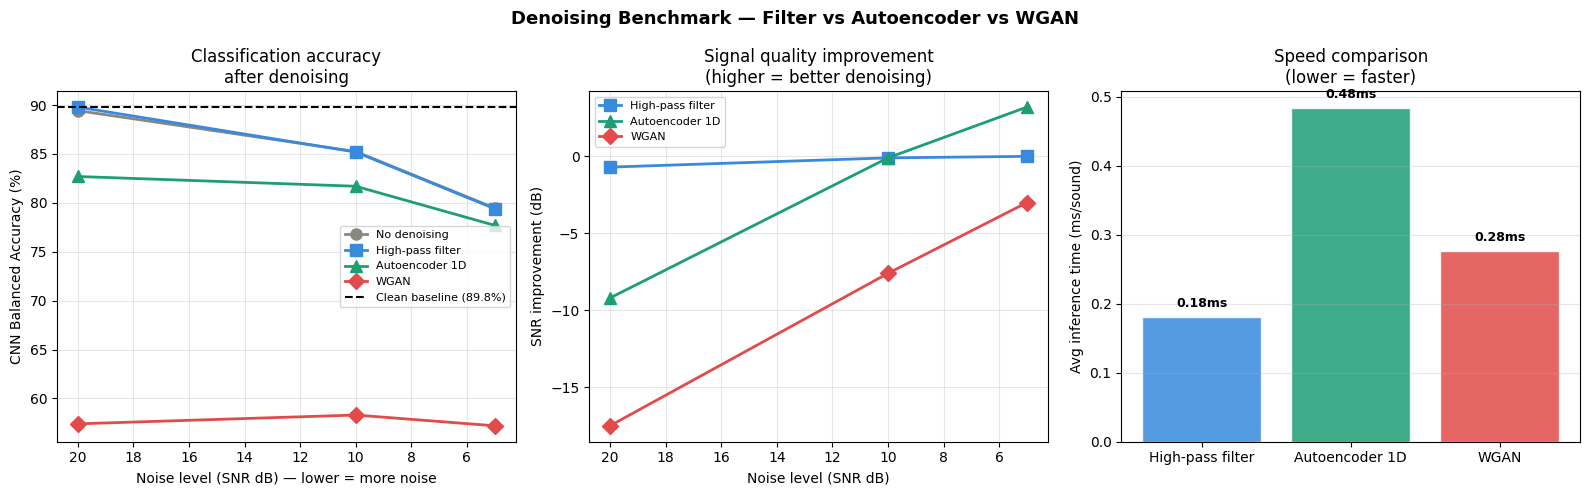

Saved: denoising_benchmark.png


In [44]:
# ── Visualization ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Denoising Benchmark — Filter vs Autoencoder vs WGAN',
             fontsize=13, fontweight='bold')

methods = ['No denoising', 'High-pass filter', 'Autoencoder 1D', 'WGAN']
colors  = ['#888780', '#378ADD', '#1D9E75', '#E24B4A']
markers = ['o', 's', '^', 'D']

# Plot 1: CNN Accuracy vs SNR level
ax1 = axes[0]
for method, color, marker in zip(methods, colors, markers):
    sub = bench_df[bench_df['Method'] == method]
    ax1.plot(sub['SNR (dB)'], sub['CNN Accuracy'],
             color=color, marker=marker, linewidth=2,
             markersize=8, label=method)
ax1.axhline(acc_clean, color='black', linestyle='--',
            linewidth=1.5, label=f'Clean baseline ({acc_clean:.1f}%)')
ax1.set_xlabel('Noise level (SNR dB) — lower = more noise')
ax1.set_ylabel('CNN Balanced Accuracy (%)')
ax1.set_title('Classification accuracy\nafter denoising')
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)
ax1.invert_xaxis()  # 20dB (mild) → 5dB (severe)

# Plot 2: SNR gain
ax2 = axes[1]
for method, color, marker in zip(methods[1:], colors[1:], markers[1:]):
    sub = bench_df[bench_df['Method'] == method]
    ax2.plot(sub['SNR (dB)'], sub['SNR gain'],
             color=color, marker=marker, linewidth=2,
             markersize=8, label=method)
ax2.set_xlabel('Noise level (SNR dB)')
ax2.set_ylabel('SNR improvement (dB)')
ax2.set_title('Signal quality improvement\n(higher = better denoising)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)
ax2.invert_xaxis()

# Plot 3: Speed comparison
ax3 = axes[2]
speed_methods = ['High-pass filter', 'Autoencoder 1D', 'WGAN']
speed_colors  = ['#378ADD', '#1D9E75', '#E24B4A']
speed_vals    = [
    np.mean([filter_results[s]['time_ms'] for s in SNR_LEVELS]),
    np.mean([ae_results[s]['time_ms']     for s in SNR_LEVELS]),
    np.mean([wgan_results[s]['time_ms']   for s in SNR_LEVELS]),
]
bars = ax3.bar(speed_methods, speed_vals,
               color=speed_colors, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, speed_vals):
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.01,
             f'{val:.2f}ms', ha='center', va='bottom',
             fontsize=9, fontweight='bold')
ax3.set_ylabel('Avg inference time (ms/sound)')
ax3.set_title('Speed comparison\n(lower = faster)')
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/denoising_benchmark.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: denoising_benchmark.png')

Our CNN is already robust:
  SNR 10dB → only -4.5% accuracy loss
  No denoising needed for moderate noise

The bottleneck isn't denoising quality
It's that any reconstruction changes the signal
distribution slightly → CNN gets confused